# 6.2 · 交易成本与滑点

> 很多回测看着赚钱，一上实盘就亏——**交易成本**是最常见的原因。
> 成本分为**显性成本**（明明白白收的费）和**隐性成本**（滑点、冲击成本、价差）。
> 本节掌握成本的构成和建模，理解"容量"和"流动性"对策略的约束。

## 一、成本的构成

| 类型 | 项目 | 大致水平（A股） |
|---|---|---|
| 显性 | 佣金 | 万 2.5（双边），最低 5 元 |
| 显性 | 印花税 | 0.05%（卖出单边，2023 年下调） |
| 显性 | 过户费 | 0.001%（双边，很小） |
| 隐性 | 买卖价差 | 买卖一价之间的差 |
| 隐性 | 滑点 | 实际成交价与预期价的偏离 |
| 隐性 | 冲击成本 | 大单把价格推高/压低 |

> 一次完整买卖（买+卖）的显性成本约 **10bps**（千一）。

## 二、滑点与买卖价差

- **买卖价差（bid-ask spread）**：你想立刻买，要付卖一价；想立刻卖，只能拿买一价。价差就是即时交易的成本。
- **滑点（slippage）**：下单后市场可能已经移动，或你的单子吃掉多档盘口，实际成交价变差。
- 流动性越差、下单越急、单子越大，滑点越严重。

> 回测里常假设按收盘价成交，但实盘有延迟和滑点，需要在回测中预先扣除。

## 三、冲击成本模型

大订单会显著推动价格（冲击成本），它是**资金容量**的核心约束。
- **线性模型**：冲击 ∝ 参与率（订单占当日成交量比例）；
- **平方根模型（Almgren-Chriss）**：冲击 ∝ √参与率，实证最常用。

参与率（participation rate）= 订单金额 / 当日成交额（ADV）。

代码在 backtest_lab.cost。

一次完整买卖 显性成本: 10.2 bps


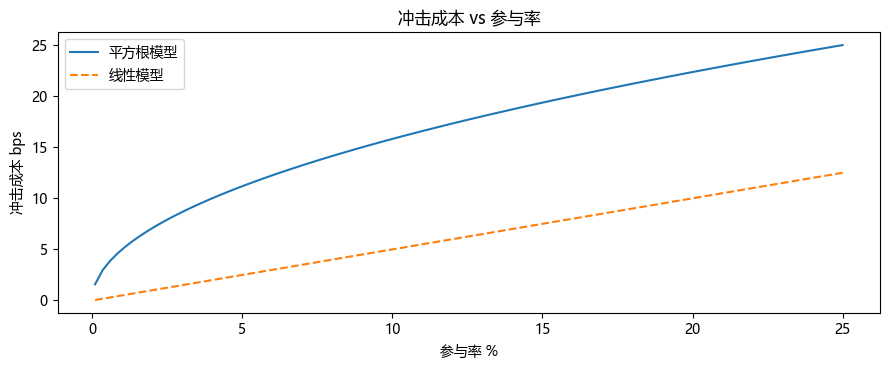

参与率    1%  冲击 5.0 bps
参与率   10%  冲击 15.8 bps
参与率   20%  冲击 22.4 bps


In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from backtest_lab.cost import (round_trip_cost_bps, impact_cost_bps,
                               total_cost_bps)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
print('一次完整买卖 显性成本: %.1f bps' % round_trip_cost_bps())
p = np.linspace(0.001, 0.25, 100)
plt.figure(figsize=(9, 3.8))
plt.plot(p*100, impact_cost_bps(p, model='sqrt'), label='平方根模型')
plt.plot(p*100, impact_cost_bps(p, model='linear'), label='线性模型', ls='--')
plt.xlabel('参与率 %'); plt.ylabel('冲击成本 bps'); plt.legend()
plt.title('冲击成本 vs 参与率'); plt.tight_layout(); plt.show()
for q in [0.01, 0.1, 0.2]:
    print('参与率 %4.0f%%  冲击 %.1f bps' % (q*100, impact_cost_bps(q)))

## 四、资金规模决定成本：策略容量

In [2]:
rows = []
for aum in [1e6, 1e8, 1e9, 5e9, 1e10]:
    adv_total = 5e11  # 沪深300 日成交额约 5000 亿
    pr = aum / adv_total
    rows.append({'资金(亿)': aum/1e8, '参与率': pr,
                 '总成本bps': total_cost_bps(0.1, participation=pr)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 资金(亿)   参与率  总成本bps
  0.01 0.000   0.581
  1.00 0.000   1.217
 10.00 0.002   2.746
 50.00 0.010   5.510
100.00 0.020   7.581


## 五、成本对策略的影响

- 资金越大、参与率越高，冲击成本急剧上升，**吃掉超额收益**；
- 每个策略都有**容量上限**：超过容量后，边际资金不再赚钱甚至亏钱；
- 小市值、高换手、低流动性策略尤其受限（前面 Top30 小市值换手很高，容量有限）。

> 降低成本的方法：降低换手、分散下单、用算法交易（TWAP/VWAP）、避开流动性差的票、在流动性好的时段交易。

## 六、小结与面试要点

- 显性成本（佣金/印花税/过户费约10bps）+ 隐性成本（价差/滑点/冲击）。
- 冲击成本：线性或平方根模型，随参与率上升；决定策略容量。
- 大资金、高换手、小市值策略成本高、容量小。

**面试高频：**
- 交易成本包含哪些？（答：佣金、印花税、过户费、价差、滑点、冲击）
- 什么是冲击成本？怎么建模？（答：大单推动价格；线性或平方根模型，函数是参与率）
- 什么是策略容量？（答：成本不超过超额收益时能容纳的最大资金）
- 怎么降低交易成本？（答：降换手、算法交易、分散、选流动性好的票）

## 动手练习
1. 用不同成本假设（0/10/30bps）回测，对比净值；
2. 估计你的策略在 1 亿、10 亿规模下的成本；
3. 实现 TWAP 思路（把大单拆成小单），讨论为什么能降冲击。

---
下一节 **6.3 严谨回测：回测陷阱、幸存者偏差、数据对齐**。